In [35]:
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
files = sorted(glob.glob("yellow_tripdata_2025-*.parquet"))

print(len(files))
print(files)

12
['yellow_tripdata_2025-01.parquet', 'yellow_tripdata_2025-02.parquet', 'yellow_tripdata_2025-03.parquet', 'yellow_tripdata_2025-04.parquet', 'yellow_tripdata_2025-05.parquet', 'yellow_tripdata_2025-06.parquet', 'yellow_tripdata_2025-07.parquet', 'yellow_tripdata_2025-08.parquet', 'yellow_tripdata_2025-09.parquet', 'yellow_tripdata_2025-10.parquet', 'yellow_tripdata_2025-11.parquet', 'yellow_tripdata_2025-12.parquet']


In [36]:
df = pd.concat(
    [pd.read_parquet(file) for file in files],
    ignore_index=True
)

print(df.shape)

(48722602, 20)


In [37]:
#print(df.columns.tolist())
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48722602 entries, 0 to 48722601
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64 

In [38]:
df.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,4.872260e+07,48722602,48722602,3.711071e+07,4.872260e+07,3.711071e+07,4.872260e+07,4.872260e+07,4.872260e+07,4.872260e+07,4.872260e+07,4.872260e+07,4.872260e+07,4.872260e+07,4.872260e+07,4.872260e+07,3.711071e+07,3.711071e+07,4.872260e+07
mean,1.860200e+00,2025-07-06 05:22:36.621956,2025-07-06 05:39:57.973506,1.295491e+00,6.842892e+00,3.225041e+00,1.615042e+02,1.611094e+02,9.372241e-01,1.841938e+01,1.164363e+00,4.776843e-01,2.842251e+00,4.988348e-01,9.503062e-01,2.690880e+01,2.183155e+00,1.451904e-01,5.294611e-01
min,1.000000e+00,2007-12-05 18:45:00,2007-12-05 19:02:00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-1.807600e+03,-1.739000e+01,-2.174000e+01,-3.333300e+02,-1.481700e+02,-1.000000e+00,-1.832850e+03,-2.500000e+00,-1.750000e+00,-7.500000e-01
25%,2.000000e+00,2025-04-08 14:04:38,2025-04-08 14:21:56,1.000000e+00,1.040000e+00,1.000000e+00,1.140000e+02,1.070000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.573000e+01,2.500000e+00,0.000000e+00,0.000000e+00
50%,2.000000e+00,2025-07-03 12:25:13,2025-07-03 12:42:35,1.000000e+00,1.850000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.000000e+00,1.358000e+01,0.000000e+00,5.000000e-01,2.000000e+00,0.000000e+00,1.000000e+00,2.135000e+01,2.500000e+00,0.000000e+00,7.500000e-01
75%,2.000000e+00,2025-10-06 13:54:53.750000,2025-10-06 14:13:21.750000,1.000000e+00,3.700000e+00,1.000000e+00,2.330000e+02,2.330000e+02,1.000000e+00,2.260000e+01,2.500000e+00,5.000000e-01,3.990000e+00,0.000000e+00,1.000000e+00,3.075000e+01,2.500000e+00,0.000000e+00,7.500000e-01
max,7.000000e+00,2025-12-31 23:59:59,2026-01-05 13:00:34,9.000000e+00,3.979944e+05,9.900000e+01,2.650000e+02,2.650000e+02,5.000000e+00,8.633721e+05,1.336000e+02,5.243380e+03,9.609400e+02,9.168700e+02,2.500000e+00,8.633804e+05,2.500000e+00,6.750000e+00,1.750000e+00
std,6.782855e-01,NaN,NaN,7.291639e-01,6.493613e+02,1.426515e+01,6.619733e+01,7.045460e+01,7.465484e-01,1.428461e+02,1.822057e+00,7.636665e-01,3.966758e+00,2.120972e+00,2.830970e-01,1.434823e+02,9.517965e-01,5.253237e-01,3.585221e-01


In [ ]:
df["pickup_hour"] = df["tpep_pickup_datetime"].dt.hour
df["pickup_month"] = df["tpep_pickup_datetime"].dt.month
df["pickup_day"] = df["tpep_pickup_datetime"].dt.day

df["duration_min"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["fare_per_mile"] = (
    df["fare_amount"] / df["trip_distance"]
).replace([float("inf"), -float("inf")], float("nan"))

df["speed_mph"] = (
    df["trip_distance"] / (df["duration_min"] / 60)
).replace([float("inf"), -float("inf")], float("nan"))

df.drop(
    columns=["tpep_pickup_datetime", "tpep_dropoff_datetime"],
    inplace=True
)
pd.options.display.float_format = '{:.2f}'.format
clean = df[
    (df["duration_min"] > 0) &
    (df["fare_amount"] > 0) &
    (df["trip_distance"] > 0) &
    (df["speed_mph"] > 0)
].copy()



In [40]:
clean.describe()

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,...,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,pickup_hour,pickup_month,pickup_day,duration_min,fare_per_mile,speed_mph
count,44171935.00,35325361.00,44171935.00,35325361.00,44171935.00,44171935.00,44171935.00,44171935.00,44171935.00,44171935.00,...,44171935.00,35325361.00,35325361.00,44171935.00,44171935.00,44171935.00,44171935.00,44171935.00,44171935.00,44171935.00
mean,1.79,1.29,6.59,3.27,162.06,161.69,0.94,20.07,1.29,0.50,...,28.89,2.28,0.15,0.55,14.21,6.62,15.58,17.62,19.38,23.47
std,0.42,0.73,616.34,14.46,65.78,70.28,0.65,149.67,1.84,0.79,...,150.21,0.70,0.50,0.33,5.99,3.44,8.70,27.47,222.32,3045.48
min,1.00,0.00,0.01,1.00,1.00,1.00,0.00,0.01,-17.39,-21.74,...,0.00,0.00,0.00,-0.75,0.00,1.00,1.00,0.02,0.00,0.00
25%,2.00,1.00,1.10,1.00,122.00,108.00,1.00,9.30,0.00,0.50,...,16.75,2.50,0.00,0.00,10.00,4.00,8.00,8.30,5.56,6.99
50%,2.00,1.00,1.89,1.00,161.00,162.00,1.00,14.20,0.00,0.50,...,22.04,2.50,0.00,0.75,15.00,7.00,15.00,13.53,7.22,9.44
75%,2.00,1.00,3.73,1.00,233.00,234.00,1.00,23.33,2.50,0.50,...,31.60,2.50,0.00,0.75,19.00,10.00,23.00,21.53,9.38,13.04
max,6.00,9.00,397994.37,99.00,265.00,265.00,5.00,863372.12,42.46,5243.38,...,863380.37,2.50,5.00,1.50,23.00,12.00,31.00,14880.77,539607.57,4034270.10


We have impossible values here, so we will drop any trips over 50 miles. 

Remove incredibly unlikely average speeds, then check how much data we lost. 

In [65]:
analysis = clean[
    (clean["speed_mph"] <= 75) &
    (clean["trip_distance"] <= 50) &
    (clean["fare_amount"] <= 150)
].copy()

print("Clean rows:", len(analysis))
print(
    "Percent retained:",
    len(analysis) / len(clean) * 100
)
# analysis.describe()
impossible_values = analysis[
    (analysis["fare_amount"] > 100) |
    (analysis["fare_per_mile"] > 10) |
    (analysis["duration_min"] > 120) |
    (analysis["speed_mph"] == 75)]
impossible_values.describe()

Clean rows: 44121359
Percent retained: 99.88550195955871


,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,...,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,pickup_hour,pickup_month,pickup_day,duration_min,fare_per_mile,speed_mph
count,9043892.00,7466583.00,9043892.00,7466583.00,9043892.00,9043892.00,9043892.00,9043892.00,9043892.00,9043892.00,...,9043892.00,7466583.00,7466583.00,9043892.00,9043892.00,9043892.00,9043892.00,9043892.00,9043892.00,9043892.00
mean,1.80,1.29,1.22,2.25,168.62,167.37,1.01,15.09,1.11,0.49,...,22.67,2.37,0.02,0.58,14.37,7.07,15.44,14.72,68.32,6.00
std,0.40,0.72,2.51,10.61,62.53,63.93,0.69,15.49,1.56,0.07,...,17.94,0.56,0.19,0.31,4.88,3.51,8.56,53.65,433.78,4.21
min,1.00,0.00,0.01,1.00,1.00,1.00,0.00,0.01,-17.39,-6.38,...,0.00,0.00,0.00,0.00,0.00,1.00,1.00,0.02,0.00,0.00
25%,2.00,1.00,0.53,1.00,137.00,138.00,1.00,7.20,0.00,0.50,...,14.28,2.50,0.00,0.75,11.00,4.00,8.00,5.67,10.91,4.16
50%,2.00,1.00,0.80,1.00,163.00,163.00,1.00,11.40,0.00,0.50,...,18.47,2.50,0.00,0.75,15.00,7.00,15.00,9.97,12.33,5.28
75%,2.00,1.00,1.24,1.00,233.00,232.00,1.00,17.00,2.50,0.50,...,24.65,2.50,0.00,0.75,18.00,10.00,23.00,16.43,15.29,6.82
max,6.00,9.00,50.00,99.00,265.00,265.00,4.00,150.00,14.25,22.14,...,975.39,2.50,1.75,1.50,23.00,12.00,31.00,14880.77,15000.00,75.00


In [61]:
bad_speed = clean[clean["speed_mph"] > 100].copy()

print("Number:", len(bad_speed))
print("Percent:", len(bad_speed) / len(clean) * 100)

bad_speed[
    [
        "VendorID",
        "trip_distance",
        "duration_min",
        "speed_mph",
        "fare_amount",
        "RatecodeID",
        "PULocationID",
        "DOLocationID"
    ]
].sort_values("speed_mph", ascending=False).head(30)

Number: 11344
Percent: 0.025681464939219894


,VendorID,trip_distance,duration_min,speed_mph,fare_amount,RatecodeID,PULocationID,DOLocationID
34819371,2,268951.34,4.00,4034270.10,5.10,NaN,114,114
47662301,2,124943.68,2.00,3748310.40,8.32,NaN,42,41
3070619,2,124083.23,2.00,3722496.90,12.14,NaN,74,75
18748174,2,103994.52,2.00,3119835.60,49.46,NaN,33,33
48439238,2,322576.17,7.00,2764938.60,6.34,NaN,82,260
31461098,2,274082.38,6.00,2740823.80,6.13,NaN,114,249
39333167,2,162631.79,4.00,2439476.85,4.69,NaN,79,107
3188501,2,276099.95,7.00,2366571.00,9.13,NaN,224,233
3107124,2,106629.95,3.00,2132599.00,12.55,NaN,186,90
39762403,2,173336.67,5.00,2080040.04,10.45,NaN,234,249


In [62]:
bad_speed["duration_min"].describe()

count   11344.00
mean        6.48
std        12.82
min         0.02
25%         0.12
50%         0.42
75%         9.65
max       465.00
Name: duration_min, dtype: float64

In [63]:
bad_speed["duration_min"].quantile(
    [0, .01, .05, .25, .5, .75, .95, .99, 1]
)

0.00     0.02
0.01     0.02
0.05     0.05
0.25     0.12
0.50     0.42
0.75     9.65
0.95    28.88
0.99    56.57
1.00   465.00
Name: duration_min, dtype: float64

In [64]:
bad_speed["trip_distance"].describe()

count    11344.00
mean     12068.36
std      36519.76
min          0.03
25%          1.40
50%          5.90
75%         31.50
max     397994.37
Name: trip_distance, dtype: float64

Hypothesis 1——Rush Hour
We believe trips are the most expensive during "rush hour", which is 3-5pm. 

In [50]:
hourly = analysis.groupby("pickup_hour").agg(
    median_fare = ("fare_amount", "median"),
    median_fare_per_mile = ("fare_per_mile", "median"),
    median_duration = ("duration_min", "median"),
    trips = ("fare_amount", "count")
).reset_index()
hourly

,pickup_hour,median_fare,median_fare_per_mile,median_duration,trips
0,0,15.60,6.10,12.85,1380208
1,1,14.79,6.05,12.00,907019
2,2,14.20,5.91,11.55,594482
3,3,14.33,5.62,11.57,403790
4,4,17.70,5.23,12.90,320336
5,5,18.27,4.98,13.12,344266
6,6,14.90,5.46,12.03,688924
7,7,14.20,6.39,12.27,1273270
8,8,14.20,7.23,13.17,1723541
9,9,14.20,7.50,13.32,1852815


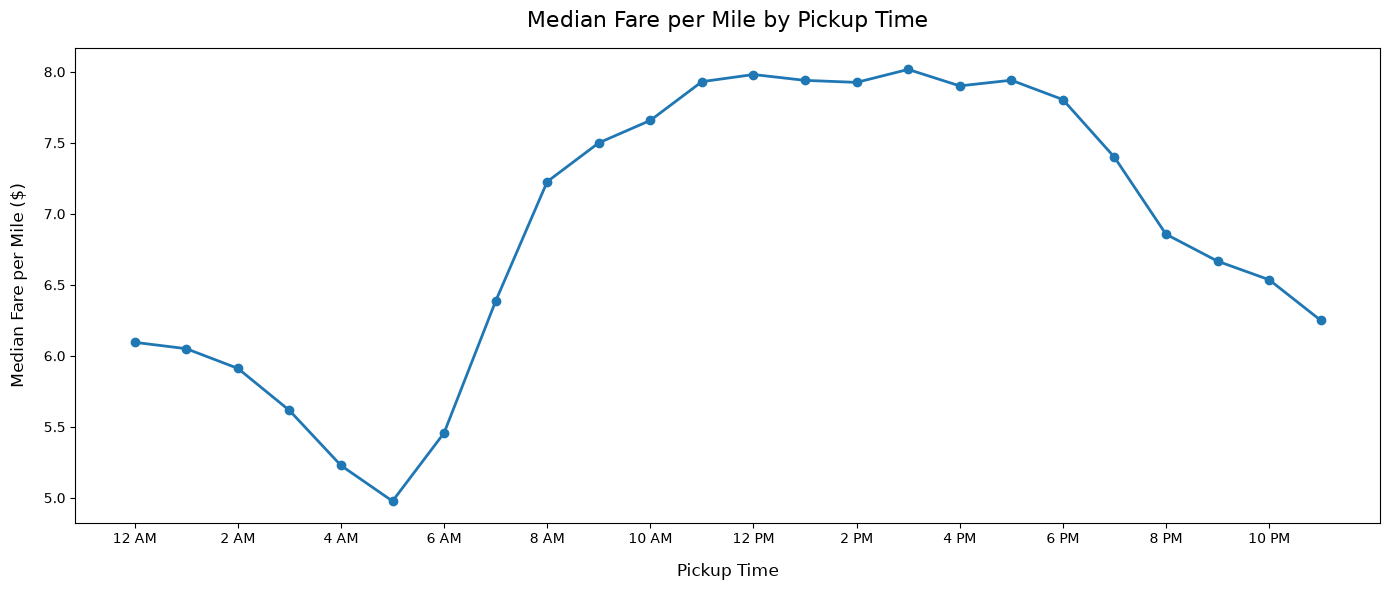

In [52]:
plt.figure(figsize=(14, 6))

plt.plot(
    range(24),
    hourly["median_fare_per_mile"],
    marker="o",
    linewidth=2
)

plt.xlabel("Pickup Time", fontsize=12, labelpad=12)
plt.ylabel("Median Fare per Mile ($)", fontsize=12, labelpad=12)
plt.title("Median Fare per Mile by Pickup Time", fontsize=16, pad=15)

tick_positions = range(0, 24, 2)

tick_labels = [
    "12 AM", "2 AM", "4 AM", "6 AM", "8 AM", "10 AM",
    "12 PM", "2 PM", "4 PM", "6 PM", "8 PM", "10 PM"
]

plt.xticks(tick_positions, tick_labels, fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

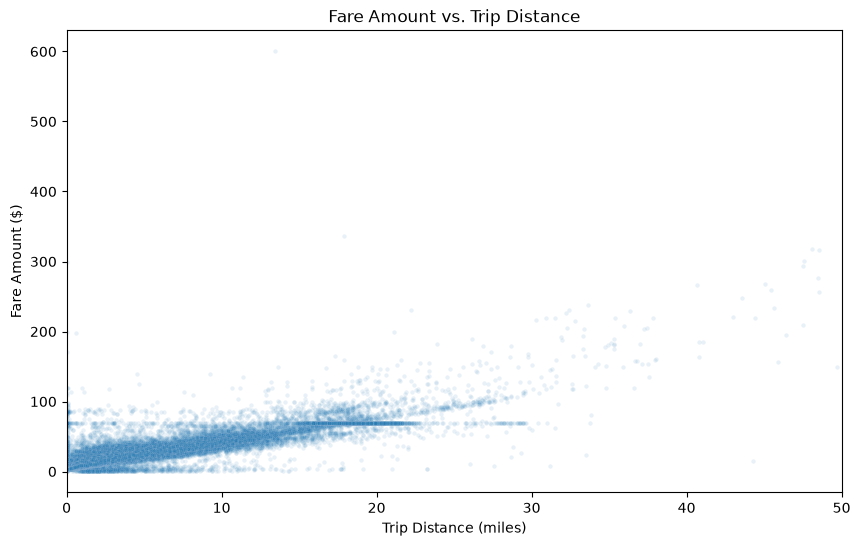

In [54]:
sample = clean.sample(n=100_000, random_state=42)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample,
    x="trip_distance",
    y="fare_amount",
    alpha=0.1,
    s=10
)
plt.xlim(0, 50)

plt.xlabel("Trip Distance (miles)")
plt.ylabel("Fare Amount ($)")
plt.title("Fare Amount vs. Trip Distance")
plt.show()

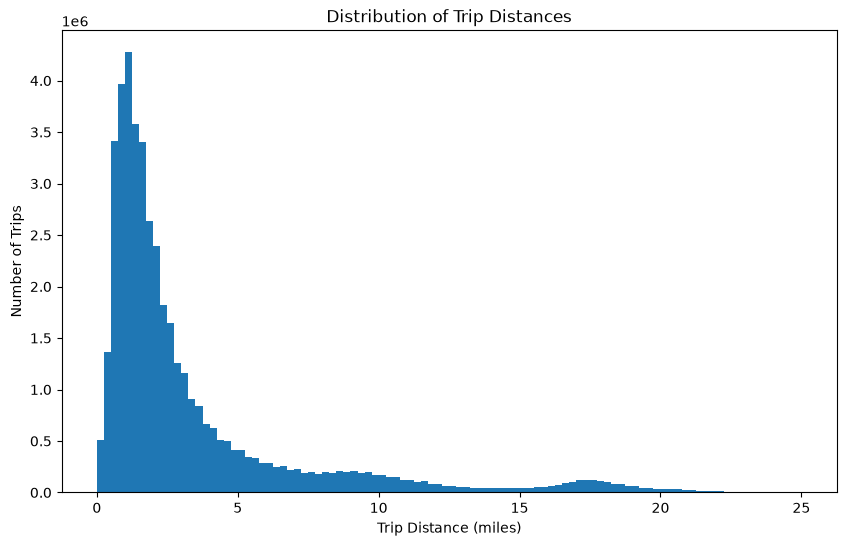

In [44]:
plt.figure(figsize=(10, 6))

plt.hist(
    clean["trip_distance"],
    bins=100,
    range=(0, 25)
)

plt.xlabel("Trip Distance (miles)")
plt.ylabel("Number of Trips")
plt.title("Distribution of Trip Distances")

plt.show()

In [45]:
long_trips = clean[
    (clean["trip_distance"] > 25) &
    (clean["trip_distance"] < 100)
].copy() #Nobody takes a taxi over 100 miles, and trips over 25 miles are rare enough to be interesting.

long_trips["speed_mph"] = (
    long_trips["trip_distance"] /
    (long_trips["duration_min"] / 60)
)

# long_trips.sort_values("speed_mph", ascending=False)[
#     ["trip_distance", "duration_min", "speed_mph", "fare_amount"]
# ].head(20)

for speed in [60, 70, 80, 100, 150, 200]:
    n = (long_trips["speed_mph"] > speed).sum()
    print(
        f">{speed} mph: {n} "
        f"({n / len(long_trips) * 100:.2f}%)"
    )
long_trips.sort_values("speed_mph", ascending=False)[
    ["VendorID", "trip_distance", "duration_min", "speed_mph", "fare_amount"]
].reset_index(drop=True).head(20)


>60 mph: 2428 (1.99%)
>70 mph: 2041 (1.68%)
>80 mph: 1796 (1.47%)
>100 mph: 1406 (1.15%)
>150 mph: 820 (0.67%)
>200 mph: 504 (0.41%)


,VendorID,trip_distance,duration_min,speed_mph,fare_amount
0,2,28.47,0.02,102492.00,106.60
1,1,35.70,0.05,42840.00,3.00
2,1,28.20,0.05,33840.00,3.00
3,2,50.55,0.10,30330.00,896.90
4,2,46.25,0.10,27750.00,719.80
5,1,32.80,0.08,23616.00,3.00
6,1,61.00,0.17,21960.00,3.00
7,1,58.10,0.17,20916.00,3.00
8,1,28.00,0.08,20160.00,156.30
9,1,31.50,0.10,18900.00,3.00
